# SNMF Feature Co-membership Analysis

This notebook measures redundancy by testing whether selected neurons belong to the same sparse co-activation features.

Pipeline:
1. Load Top-K and MMR masks.
2. Collect layer-wise post-activation matrices on 30,000 Wikipedia tokens per language.
3. Factorize each matrix with semi-NMF.
4. Compare feature coverage and within-layer co-membership rates.
5. Validate co-membership against token-level Jaccard similarity.


In [3]:
import os
from pathlib import Path

In [4]:
import json, math, random, gc, itertools
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


MODEL_NAME = "meta-llama/Llama-2-7b-hf"
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"
LANGS      = ["en", "zh", "fr", "es", "vi", "id", "ja"]

def find_repo_root():
    bases = [Path.cwd(), *Path.cwd().parents]
    candidates = [path for base in bases for path in (base, base / "Less_But_Sharper")]
    for path in candidates:
        if (path / "artifacts" / "masks").is_dir() and (path / "code" / "analysis").is_dir():
            return path.resolve()
    raise RuntimeError("Could not locate the Less_But_Sharper repository root.")


PACKAGE_ROOT = find_repo_root()
MASK_DIR = PACKAGE_ROOT / "artifacts" / "masks"
TOPK_PATH = MASK_DIR / "llama2_topk_k30.pth"
MMR_PATH = MASK_DIR / "llama2_mmr_k30_lambda0.6.pth"
CANDIDATE_PATH = PACKAGE_ROOT / "work" / "llama2-7b" / "llama2-7b.neuron.pth"

DATA_DIR = PACKAGE_ROOT / "work" / "analysis" / "snmf"
ACT_DIR  = os.path.join(DATA_DIR, "acts")
FAC_DIR  = os.path.join(DATA_DIR, "snmf")
for d in (DATA_DIR, ACT_DIR, FAC_DIR):
    os.makedirs(d, exist_ok=True)

T_TOKENS      = 30_000
CTX_LEN       = 1024
SNMF_K        = 50
SNMF_SPARSITY = 0.01
SNMF_MAX_ITER = 800
SNMF_INIT     = "svd"
DELETE_ACTS_AFTER_FIT = False
SEED = 0

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"device={DEVICE}")

/home/lar/miniconda3/envs/lang-neuron/lib/python3.10/site-packages/torch/cuda/__init__.py:51: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


device=cuda


## 1. Load neuron masks

Normalize supported mask formats to `{language: [(layer, neuron), ...]}`.


In [5]:
raw_topk = torch.load(TOPK_PATH, map_location="cpu")
raw_mmr  = torch.load(MMR_PATH,  map_location="cpu")
raw_candidates = torch.load(CANDIDATE_PATH, map_location="cpu") if CANDIDATE_PATH.is_file() else None

def peek(obj, name, depth=0, max_depth=2):
    pad = "  " * depth
    if torch.is_tensor(obj):
        print(f"{pad}{name}: Tensor{tuple(obj.shape)} dtype={obj.dtype}")
    elif isinstance(obj, dict):
        print(f"{pad}{name}: dict keys={list(obj.keys())[:12]}")
        if depth < max_depth:
            for k in list(obj.keys())[:3]:
                peek(obj[k], f"[{k!r}]", depth + 1, max_depth)
    elif isinstance(obj, (list, tuple)):
        print(f"{pad}{name}: {type(obj).__name__} len={len(obj)} head={obj[:3]}")
    else:
        print(f"{pad}{name}: {type(obj).__name__} = {obj}")

print("=== llama2_topk_k30.pth ==="); peek(raw_topk, "root")
print("\n=== llama2_mmr_k30_lambda0.6.pth ==="); peek(raw_mmr, "root")
print("\n=== candidates.pth ==="); peek(raw_candidates, "root")

=== topk_K30.pth ===
root: list len=7 head=[[tensor([ 1241,  2369,  4729,  6811,  9190, 10353]), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([5759, 9750]), tensor([ 1797, 10913]), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([3954]), tensor([ 690, 8564]), tensor([6455]), tensor([670]), tensor([], dtype=torch.int64), tensor([3007]), tensor([1301]), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([5679]), tensor([3894, 9967]), tensor([], dtype=torch.int64), tensor([4268]), tensor([], dtype=torch.int64), tensor([10465]), tensor([], dtype=torch.int64), tensor([9667]), tensor([ 721, 2657]), tensor([], dtype=torch.int64), tensor([ 449, 1433, 5533, 5574, 7789]), tensor([], dtype=torch.int64)], [tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype=torch.int64), tensor([], dtype

In [6]:
def normalize_mask(raw, langs=LANGS):
    '''Normalize masks to {language: [(layer, neuron), ...]}.'''
    out = {}

    if isinstance(raw, list) and len(raw) == len(langs):
        for li, lang in enumerate(langs):
            pairs = []
            for l, idxs in enumerate(raw[li]):
                idxs = idxs.tolist() if torch.is_tensor(idxs) else list(idxs)
                pairs += [(int(l), int(j)) for j in idxs]
            out[lang] = pairs
        return out

    if isinstance(raw, dict):
        for lang in langs:
            if lang not in raw:
                print(f"[warn] '{lang}' is missing. keys={list(raw.keys())[:10]}")
                continue
            v = raw[lang]
            if torch.is_tensor(v):
                if v.dtype == torch.bool:
                    out[lang] = [tuple(map(int, x)) for x in v.nonzero(as_tuple=False).tolist()]
                elif v.ndim == 2 and v.shape[1] == 2:
                    out[lang] = [tuple(map(int, r)) for r in v.tolist()]
                else:
                    raise ValueError(f"{lang}: Unsupported tensor shape {tuple(v.shape)}")
            elif isinstance(v, dict):
                pairs = []
                for l, idxs in v.items():
                    idxs = idxs.tolist() if torch.is_tensor(idxs) else idxs
                    pairs += [(int(l), int(j)) for j in idxs]
                out[lang] = pairs
            elif isinstance(v, (list, tuple)):
                out[lang] = [tuple(map(int, p)) for p in v]
            else:
                raise ValueError(f"{lang}: Unsupported value type {type(v)}")
        return out
    raise ValueError(f"Unsupported top-level format: {type(raw)} (len={len(raw) if hasattr(raw,'__len__') else '?'})")

sel_topk = normalize_mask(raw_topk)
sel_mmr  = normalize_mask(raw_mmr)


sel_cand = None
if CANDIDATE_PATH and os.path.exists(CANDIDATE_PATH):
    sel_cand = normalize_mask(torch.load(CANDIDATE_PATH, map_location="cpu"))


RELEVANT_LAYERS = {}
for lang in LANGS:
    layers = {l for l, _ in sel_topk.get(lang, [])} | {l for l, _ in sel_mmr.get(lang, [])}
    if sel_cand is not None:
        layers |= {l for l, _ in sel_cand.get(lang, [])}
    RELEVANT_LAYERS[lang] = sorted(layers)

for lang in LANGS:
    nt, nm = len(sel_topk.get(lang, [])), len(sel_mmr.get(lang, []))
    flag = "" if (nt == 30 and nm == 30) else "  <-- check language order"
    print(f"{lang}: topk={nt} mmr={nm} "
          f"| layers({len(RELEVANT_LAYERS[lang])})={RELEVANT_LAYERS[lang]}{flag}")

en: topk=30 mmr=30 | layers(23)=[0, 4, 5, 7, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 25, 26, 27, 28, 29, 30, 31]
zh: topk=30 mmr=30 | layers(31)=[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
fr: topk=30 mmr=30 | layers(31)=[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
es: topk=30 mmr=30 | layers(29)=[0, 1, 2, 4, 5, 6, 7, 9, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
vi: topk=30 mmr=30 | layers(30)=[0, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
id: topk=30 mmr=30 | layers(30)=[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
ja: topk=30 mmr=30 | layers(30)=[0, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]


## 2. Collect activations

Collect `SiLU(gate_proj(x))` activations to match the LAPE and Jaccard definitions used in the paper. Each layer requires approximately 630 MB for a `11008 × 30000` float16 matrix.


In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def get_token_ids(lang, T=T_TOKENS):
    '''Load and cache T contiguous Wikipedia tokens per language.'''
    cache = os.path.join(ACT_DIR, f"tokens_{lang}_{T}.pt")
    if os.path.exists(cache):
        return torch.load(cache)
    ds = load_dataset("wikimedia/wikipedia", f"20231101.{lang}",
                      split="train", streaming=True)
    ids = []
    for ex in ds:
        ids += tokenizer(ex["text"], add_special_tokens=False)["input_ids"]
        if len(ids) >= T:
            break
    ids = torch.tensor(ids[:T], dtype=torch.long)
    torch.save(ids, cache)
    return ids

/home/lar/miniconda3/envs/lang-neuron/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [8]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, torch_dtype=torch.float16, device_map=DEVICE)
model.eval()
D_A = model.config.intermediate_size
N_LAYERS = model.config.num_hidden_layers

@torch.no_grad()
def collect_activations(lang, layers, T=T_TOKENS, ctx_len=CTX_LEN):
    '''Collect and cache float16 post-activations for selected layers.'''
    todo = [l for l in layers
            if not os.path.exists(os.path.join(ACT_DIR, f"acts_{lang}_l{l}.pt"))]
    if not todo:
        print(f"[{lang}] all layer caches found; skipping")
        return
    ids = get_token_ids(lang, T)
    store = {l: [] for l in todo}
    hooks = []
    def make_hook(l):
        def hook(module, inp, out):
            store[l].append(out.detach().to(torch.float16).cpu())
        return hook
    for l in todo:
        hooks.append(model.model.layers[l].mlp.act_fn.register_forward_hook(make_hook(l)))
    try:
        for s in range(0, T, ctx_len):
            chunk = ids[s:s + ctx_len].unsqueeze(0).to(DEVICE)
            model(chunk)
    finally:
        for h in hooks:
            h.remove()
    for l in todo:
        A = torch.cat([x.squeeze(0) for x in store[l]], dim=0).T.contiguous()
        torch.save(A, os.path.join(ACT_DIR, f"acts_{lang}_l{l}.pt"))
        print(f"[{lang}] layer {l}: A={tuple(A.shape)} saved")
    del store; gc.collect(); torch.cuda.empty_cache()

for lang in LANGS:
    collect_activations(lang, RELEVANT_LAYERS[lang])

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/home/lar/miniconda3/envs/lang-neuron/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


[en] all layer caches found; skipping
[zh] all layer caches found; skipping
[fr] all layer caches found; skipping
[es] all layer caches found; skipping
[vi] all layer caches found; skipping
[id] all layer caches found; skipping
[ja] all layer caches found; skipping


## 3. Fit semi-NMF

Factorize each layer as `A ≈ ZY` using low-rank SVD initialization, WTA sparsity, and multiplicative updates.


In [9]:

@torch.no_grad()
def init_svd(A, K, eps=1e-6):
    U, S, V = torch.svd_lowrank(A, q=min(K + 10, min(A.shape)), niter=4)
    U, S, V = U[:, :K], S[:K], V[:, :K]
    sroot = S.sqrt()
    F_init = U * sroot.unsqueeze(0)
    G_init = (V * sroot.unsqueeze(0)).clamp_min(eps)
    return F_init, G_init

def wta_features(F, pct_keep=0.05, by_abs=True):
    d, K = F.shape
    k = max(1, math.ceil(pct_keep * d))
    scores = F.abs() if by_abs else F
    topk_vals, _ = torch.topk(scores, k, dim=0, sorted=True)
    thresh = topk_vals[-1, :]
    F.mul_(scores >= thresh.unsqueeze(0))

def fix_hoyer_scale(F, G, eps=1e-8):
    col_norms = G.norm(dim=0, keepdim=True).clamp_min(eps)
    G.div_(col_norms); F.mul_(col_norms.squeeze(0))

def _pos(X): return (X.abs() + X) * 0.5
def _neg(X): return (X.abs() - X) * 0.5

class NMFSemiNMF(nn.Module):
    def __init__(self, rank, fitting_device="cpu", sparsity=0.01):
        super().__init__()
        self.rank, self.fitting_device, self.sparsity = rank, fitting_device, sparsity
        self.F_ = None; self.G_ = None

    def fit(self, A, max_iter=500, tol=1e-4, reg=1e-6, patience=100,
            verbose=True, init="random"):
        A = A.to(self.fitting_device)
        mlp_dim, num_samples = A.shape
        K = self.rank
        if init == "svd":
            F0, G0 = init_svd(A, K)
        else:
            G0 = torch.rand(num_samples, K, device=self.fitting_device).clamp_min(1e-6)
            F0 = torch.randn(mlp_dim, K, device=self.fitting_device)
        self.G_ = nn.Parameter(G0.to(self.fitting_device))
        self.F_ = nn.Parameter(F0.to(self.fitting_device))
        best_loss, best_F, best_G, no_imp = float("inf"), None, None, 0
        with torch.no_grad():
            eye = torch.eye(K, device=self.fitting_device) * reg
            for it in range(max_iter):
                inv = torch.linalg.inv(self.G_.T @ self.G_ + eye)
                self.F_.data.copy_(A @ self.G_ @ inv)
                wta_features(self.F_, pct_keep=self.sparsity)
                fix_hoyer_scale(self.F_, self.G_)
                P, Q = A.T @ self.F_, self.F_.T @ self.F_
                numer = _pos(P) + self.G_ @ _neg(Q)
                denom = _neg(P) + self.G_ @ _pos(Q)
                self.G_.data.copy_(self.G_ * torch.sqrt(numer / (denom + 1e-6)))
                loss = torch.norm(A - self.F_ @ self.G_.T, p="fro") ** 2
                if loss.item() < best_loss - tol:
                    best_loss, no_imp = loss.item(), 0
                    best_F, best_G = self.F_.data.clone(), self.G_.data.clone()
                else:
                    no_imp += 1
                if verbose and it % 100 == 0:
                    print(f"  iter {it:4d} loss={loss.item():.4e} (best={best_loss:.4e})")
                if no_imp >= patience:
                    break
        if best_F is not None:
            self.F_.data.copy_(best_F); self.G_.data.copy_(best_G)
        return self

In [10]:
def snmf_path(lang, l, k=SNMF_K):
    return os.path.join(FAC_DIR, f"snmf_{lang}_l{l}_k{k}_p{SNMF_SPARSITY}.pt")

def run_snmf_for_lang(lang, layers, k=SNMF_K):
    for l in layers:
        out = snmf_path(lang, l, k)
        if os.path.exists(out):
            continue
        A = torch.load(os.path.join(ACT_DIR, f"acts_{lang}_l{l}.pt")).float().to(DEVICE)
        print(f"[{lang}] layer {l}: SNMF k={k} fitting (A={tuple(A.shape)})")
        m = NMFSemiNMF(rank=k, fitting_device=DEVICE, sparsity=SNMF_SPARSITY)
        m.fit(A, max_iter=SNMF_MAX_ITER, init=SNMF_INIT, verbose=True)
        Z = m.F_.detach().cpu()
        Y = m.G_.detach().cpu().T
        torch.save({"Z": Z, "Y": Y}, out)
        del A, m; gc.collect(); torch.cuda.empty_cache()
        if DELETE_ACTS_AFTER_FIT:
            os.remove(os.path.join(ACT_DIR, f"acts_{lang}_l{l}.pt"))

for lang in LANGS:
    run_snmf_for_lang(lang, RELEVANT_LAYERS[lang])

## 4. Measure feature co-membership

For each language and selection method, report distinct primary features, neurons per feature, and the within-layer pair co-membership rate. Cross-layer pairs are not compared because features are layer-specific.


In [11]:
def load_Z(lang, l, k=SNMF_K):
    return torch.load(snmf_path(lang, l, k))["Z"]

def neuron_features(Z, j):
    '''Return feature memberships for neuron j.'''
    return set(torch.nonzero(Z[j] != 0).flatten().tolist())

def comembership_metrics(selected, lang, k=SNMF_K):
    Zs = {}
    feats, primary = {}, {}
    for (l, j) in selected:
        if l not in Zs:
            Zs[l] = load_Z(lang, l, k)
        Z = Zs[l]
        fs = neuron_features(Z, j)
        feats[(l, j)] = fs
        primary[(l, j)] = (l, int(torch.argmax(Z[j].abs()))) if fs else None

    assigned = [p for p in primary.values() if p is not None]
    n_distinct = len(set(assigned))


    by_layer = defaultdict(list)
    for (l, j) in selected:
        by_layer[l].append((l, j))
    n_pairs = n_share = 0
    share_flags = []
    for l, ns in by_layer.items():
        for a, b in itertools.combinations(ns, 2):
            n_pairs += 1
            shared = len(feats[a] & feats[b]) > 0
            n_share += shared
            share_flags.append((a, b, shared))

    return {
        "n_selected": len(selected),
        "n_assigned": len(assigned),
        "n_distinct_feat": n_distinct,
        "neurons_per_feat": len(assigned) / max(n_distinct, 1),
        "n_within_layer_pairs": n_pairs,
        "n_comem_pairs": n_share,
        "pair_comem_rate": n_share / n_pairs if n_pairs else float("nan"),
    }, share_flags

In [12]:
import pandas as pd

rows, flags_store = [], {}
for lang in LANGS:
    for method, sel in [("Top-K", sel_topk.get(lang, [])),
                        ("MMR",   sel_mmr.get(lang, []))]:
        if not sel:
            continue
        m, flags = comembership_metrics(sel, lang)
        m.update(lang=lang, method=method)
        rows.append(m)
        flags_store[(lang, method)] = flags

df = pd.DataFrame(rows)[
    ["lang", "method", "n_selected", "n_assigned", "n_distinct_feat",
     "neurons_per_feat", "n_within_layer_pairs", "n_comem_pairs", "pair_comem_rate"]
]
display(df)


summary = df.groupby("method")[
    ["n_distinct_feat", "neurons_per_feat", "pair_comem_rate"]].mean().round(3)
print("\n=== Method averages ==="); display(summary)
df.to_csv(os.path.join(DATA_DIR, "analysis1_comembership.csv"), index=False)

,lang,method,n_selected,n_assigned,n_distinct_feat,neurons_per_feat,n_within_layer_pairs,n_comem_pairs,pair_comem_rate
0,en,Top-K,30,27,22,1.227273,30,13,0.433333
1,en,MMR,30,24,22,1.090909,53,14,0.264151
2,zh,Top-K,30,29,20,1.450000,55,46,0.836364
3,zh,MMR,30,26,21,1.238095,32,20,0.625000
4,fr,Top-K,30,26,21,1.238095,23,12,0.521739
5,fr,MMR,30,19,15,1.266667,36,5,0.138889
6,es,Top-K,30,30,24,1.250000,21,21,1.000000
7,es,MMR,30,27,26,1.038462,29,6,0.206897
8,vi,Top-K,30,27,20,1.350000,25,17,0.680000
9,vi,MMR,30,20,20,1.000000,99,5,0.050505



=== Method averages ===


,n_distinct_feat,neurons_per_feat,pair_comem_rate
method,,,
MMR,20.857,1.124,0.265
Top-K,21.714,1.292,0.658


### 4.1 Significance tests

Use Fisher's exact test for per-language and pooled within-layer pair counts.


In [13]:
from scipy.stats import fisher_exact

test_rows = []
pool = {"Top-K": [0, 0], "MMR": [0, 0]}
for lang in LANGS:
    t = df[(df.lang == lang) & (df.method == "Top-K")]
    m = df[(df.lang == lang) & (df.method == "MMR")]
    if t.empty or m.empty:
        continue
    a, b = int(t.n_comem_pairs), int(t.n_within_layer_pairs) - int(t.n_comem_pairs)
    c, d = int(m.n_comem_pairs), int(m.n_within_layer_pairs) - int(m.n_comem_pairs)
    pool["Top-K"][0] += a; pool["Top-K"][1] += b
    pool["MMR"][0]  += c; pool["MMR"][1]  += d
    if (a + b) and (c + d):
        odds, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        test_rows.append(dict(lang=lang, topk_rate=a / (a + b), mmr_rate=c / (c + d),
                              odds_ratio=odds, p_value=p))
tests = pd.DataFrame(test_rows); display(tests)

odds, p = fisher_exact([pool["Top-K"], pool["MMR"]], alternative="greater")
print(f"\nPooled Fisher exact (Top-K rate > MMR rate): OR={odds:.2f}, p={p:.3g}")

/tmp/ipykernel_1066703/2224601214.py:10: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  a, b = int(t.n_comem_pairs), int(t.n_within_layer_pairs) - int(t.n_comem_pairs)
/tmp/ipykernel_1066703/2224601214.py:11: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  c, d = int(m.n_comem_pairs), int(m.n_within_layer_pairs) - int(m.n_comem_pairs)


,lang,topk_rate,mmr_rate,odds_ratio,p_value
0,en,0.433333,0.264151,2.130252,9.134061e-02
1,zh,0.836364,0.625000,3.066667,2.603297e-02
2,fr,0.521739,0.138889,6.763636,2.101794e-03
3,es,1.000000,0.206897,inf,4.396573e-09
4,vi,0.680000,0.050505,39.950000,5.682310e-11
5,id,0.227273,0.028902,9.882353,6.389115e-05
6,ja,0.904762,0.540541,8.075000,2.683521e-04



Pooled Fisher exact (Top-K rate > MMR rate): OR=9.68, p=1.05e-38


### 4.2 Random-selection baseline

When a candidate pool is available, estimate the null co-membership distribution from 200 random selections.


In [14]:
if sel_cand is not None:
    N_BOOT = 200
    null_rows = []
    for lang in LANGS:
        cand = sel_cand.get(lang, [])
        if len(cand) < 30:
            continue
        rates = []
        for _ in range(N_BOOT):
            samp = random.sample(cand, 30)
            m, _ = comembership_metrics(samp, lang)
            rates.append(m["pair_comem_rate"])
        rates = np.array([r for r in rates if not math.isnan(r)])
        tk = df[(df.lang == lang) & (df.method == "Top-K")].pair_comem_rate.iloc[0]
        mm = df[(df.lang == lang) & (df.method == "MMR")].pair_comem_rate.iloc[0]
        null_rows.append(dict(
            lang=lang, null_mean=rates.mean(), null_std=rates.std(),
            topk=tk, mmr=mm,
            p_topk_gt_null=float((rates >= tk).mean()),
            p_mmr_lt_null=float((rates <= mm).mean())))
    display(pd.DataFrame(null_rows).round(4))
else:
    print("CANDIDATE_PATH is not set; skipping the random baseline.")

,lang,null_mean,null_std,topk,mmr,p_topk_gt_null,p_mmr_lt_null
0,en,0.4335,0.1333,0.4333,0.2642,0.455,0.100
1,zh,0.2547,0.1311,0.8364,0.6250,0.000,0.985
2,fr,0.1824,0.1030,0.5217,0.1389,0.000,0.380
3,es,0.1976,0.1084,1.0000,0.2069,0.000,0.595
4,vi,0.0703,0.0540,0.6800,0.0505,0.000,0.460
5,id,0.1668,0.0920,0.2273,0.0289,0.240,0.030
6,ja,0.2582,0.1305,0.9048,0.5405,0.000,0.965


## 5. Visualizations


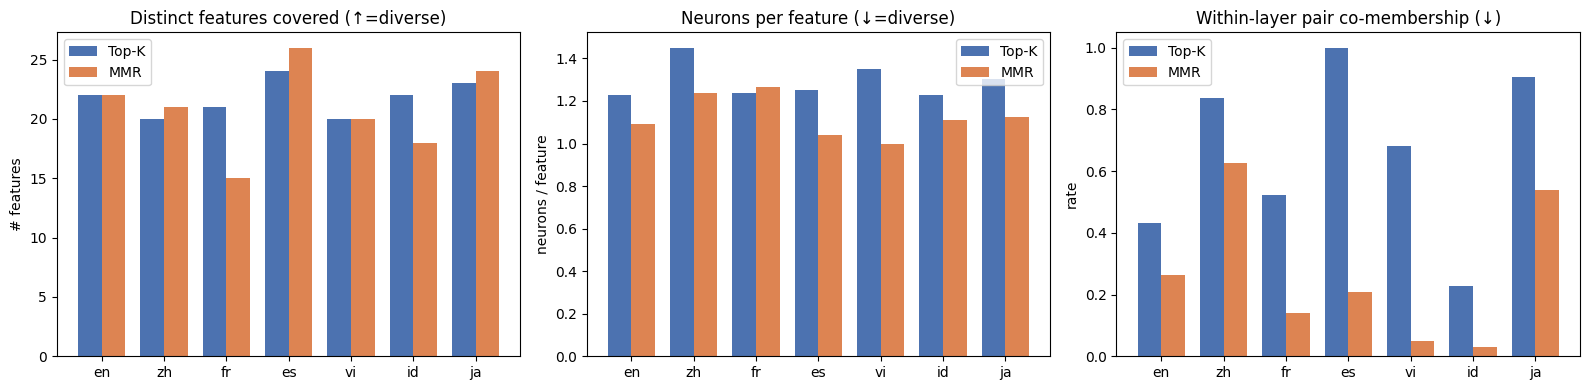

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
langs_present = [l for l in LANGS if l in df.lang.values]
x = np.arange(len(langs_present)); w = 0.38

def bars(ax, col, title, ylabel):
    tk = [df[(df.lang == l) & (df.method == "Top-K")][col].iloc[0] for l in langs_present]
    mm = [df[(df.lang == l) & (df.method == "MMR")][col].iloc[0] for l in langs_present]
    ax.bar(x - w / 2, tk, w, label="Top-K", color="#4C72B0")
    ax.bar(x + w / 2, mm, w, label="MMR",  color="#DD8452")
    ax.set_xticks(x); ax.set_xticklabels(langs_present)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.legend()

bars(axes[0], "n_distinct_feat",  "Distinct features covered (↑=diverse)", "# features")
bars(axes[1], "neurons_per_feat", "Neurons per feature (↓=diverse)",       "neurons / feature")
bars(axes[2], "pair_comem_rate",  "Within-layer pair co-membership (↓)",   "rate")
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "analysis1_bars.png"), dpi=200)
plt.show()

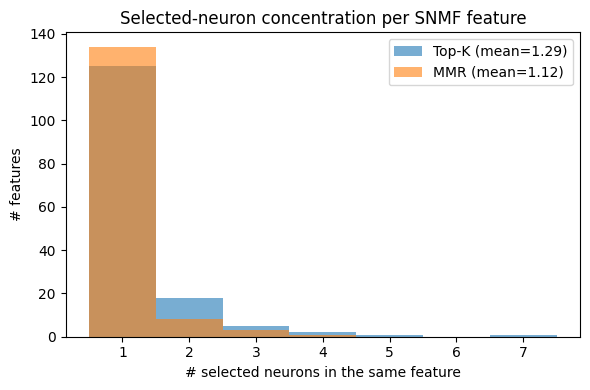

In [16]:

def feat_counts(sel_all, k=SNMF_K):
    cnt = defaultdict(int)
    for lang in LANGS:
        Zs = {}
        for (l, j) in sel_all.get(lang, []):
            if (lang, l) not in Zs:
                Zs[(lang, l)] = load_Z(lang, l, k)
            Z = Zs[(lang, l)]
            fs = neuron_features(Z, j)
            if fs:
                f = int(torch.argmax(Z[j].abs()))
                cnt[(lang, l, f)] += 1
    return list(cnt.values())

c_tk, c_mm = feat_counts(sel_topk), feat_counts(sel_mmr)
bins = np.arange(0.5, max(c_tk + c_mm) + 1.5)
plt.figure(figsize=(6, 4))
plt.hist(c_tk, bins=bins, alpha=0.6, label=f"Top-K (mean={np.mean(c_tk):.2f})")
plt.hist(c_mm, bins=bins, alpha=0.6, label=f"MMR (mean={np.mean(c_mm):.2f})")
plt.xlabel("# selected neurons in the same feature"); plt.ylabel("# features")
plt.title("Selected-neuron concentration per SNMF feature"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "analysis1_hist.png"), dpi=200)
plt.show()

## 6. Jaccard validation

Compare Jaccard similarity for co-member and non-co-member Top-K pairs with a Mann–Whitney U test.


Co-member pair Jaccard: mean=0.793 (n=157)
Non-co-member pair   : mean=0.672 (n=83)
Mann-Whitney U (greater): U=10861, p=1e-17


/tmp/ipykernel_1066703/2496416030.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([jac_shared, jac_unshared], labels=["co-member", "non-co-member"])


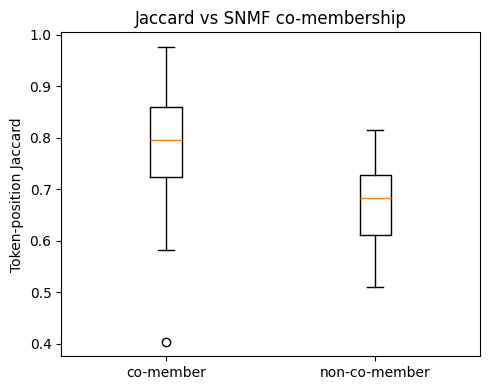

In [17]:
from scipy.stats import mannwhitneyu

def pair_jaccard(lang, a, b):
    (l1, j1), (l2, j2) = a, b
    assert l1 == l2
    A = torch.load(os.path.join(ACT_DIR, f"acts_{lang}_l{l1}.pt"))
    s1, s2 = (A[j1] > 0), (A[j2] > 0)
    inter = (s1 & s2).sum().item(); union = (s1 | s2).sum().item()
    return inter / union if union else float("nan")

if not DELETE_ACTS_AFTER_FIT:
    jac_shared, jac_unshared = [], []
    for (lang, method), flags in flags_store.items():
        if method != "Top-K":
            continue
        for a, b, shared in flags:
            v = pair_jaccard(lang, a, b)
            (jac_shared if shared else jac_unshared).append(v)
    if jac_shared and jac_unshared:
        u, p = mannwhitneyu(jac_shared, jac_unshared, alternative="greater")
        print(f"Co-member pair Jaccard: mean={np.mean(jac_shared):.3f} (n={len(jac_shared)})")
        print(f"Non-co-member pair   : mean={np.mean(jac_unshared):.3f} (n={len(jac_unshared)})")
        print(f"Mann-Whitney U (greater): U={u:.0f}, p={p:.3g}")
        plt.figure(figsize=(5, 4))
        plt.boxplot([jac_shared, jac_unshared], labels=["co-member", "non-co-member"])
        plt.ylabel("Token-position Jaccard"); plt.title("Jaccard vs SNMF co-membership")
        plt.tight_layout(); plt.show()
    else:
        print("Insufficient pairs for comparison.")
else:
    print("Activation files are unavailable; skipping Jaccard validation.")

## 7. Activation matrix inspection


In [18]:

import os, torch, numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

LANGS = ["en", "zh", "fr", "es", "vi", "id", "ja"]
ACT_DIR = PACKAGE_ROOT / "work" / "analysis" / "snmf" / "acts"
MASK_DIR = PACKAGE_ROOT / "artifacts" / "masks"

def normalize_mask(raw, langs=LANGS):
    out = {}
    for li, lang in enumerate(langs):
        pairs = []
        for l, idxs in enumerate(raw[li]):
            idxs = idxs.tolist() if torch.is_tensor(idxs) else list(idxs)
            pairs += [(int(l), int(j)) for j in idxs]
        out[lang] = pairs
    return out

sel_topk = normalize_mask(torch.load(MASK_DIR / "llama2_topk_k30.pth", map_location="cpu"))
sel_mmr  = normalize_mask(torch.load(MASK_DIR / "llama2_mmr_k30_lambda0.6.pth", map_location="cpu"))

_A = {}
def load_A(lang, l):
    if (lang, l) not in _A:
        _A[(lang, l)] = torch.load(f"{ACT_DIR}/acts_{lang}_l{l}.pt").float()
    return _A[(lang, l)]

def by_layer(sel):
    d = defaultdict(list)
    for l, j in sel: d[l].append(j)
    return dict(sorted(d.items()))

print("ready.", {lg: (len(sel_topk[lg]), len(sel_mmr[lg])) for lg in LANGS})

ready. {'en': (30, 30), 'zh': (30, 30), 'fr': (30, 30), 'es': (30, 30), 'vi': (30, 30), 'id': (30, 30), 'ja': (30, 30)}


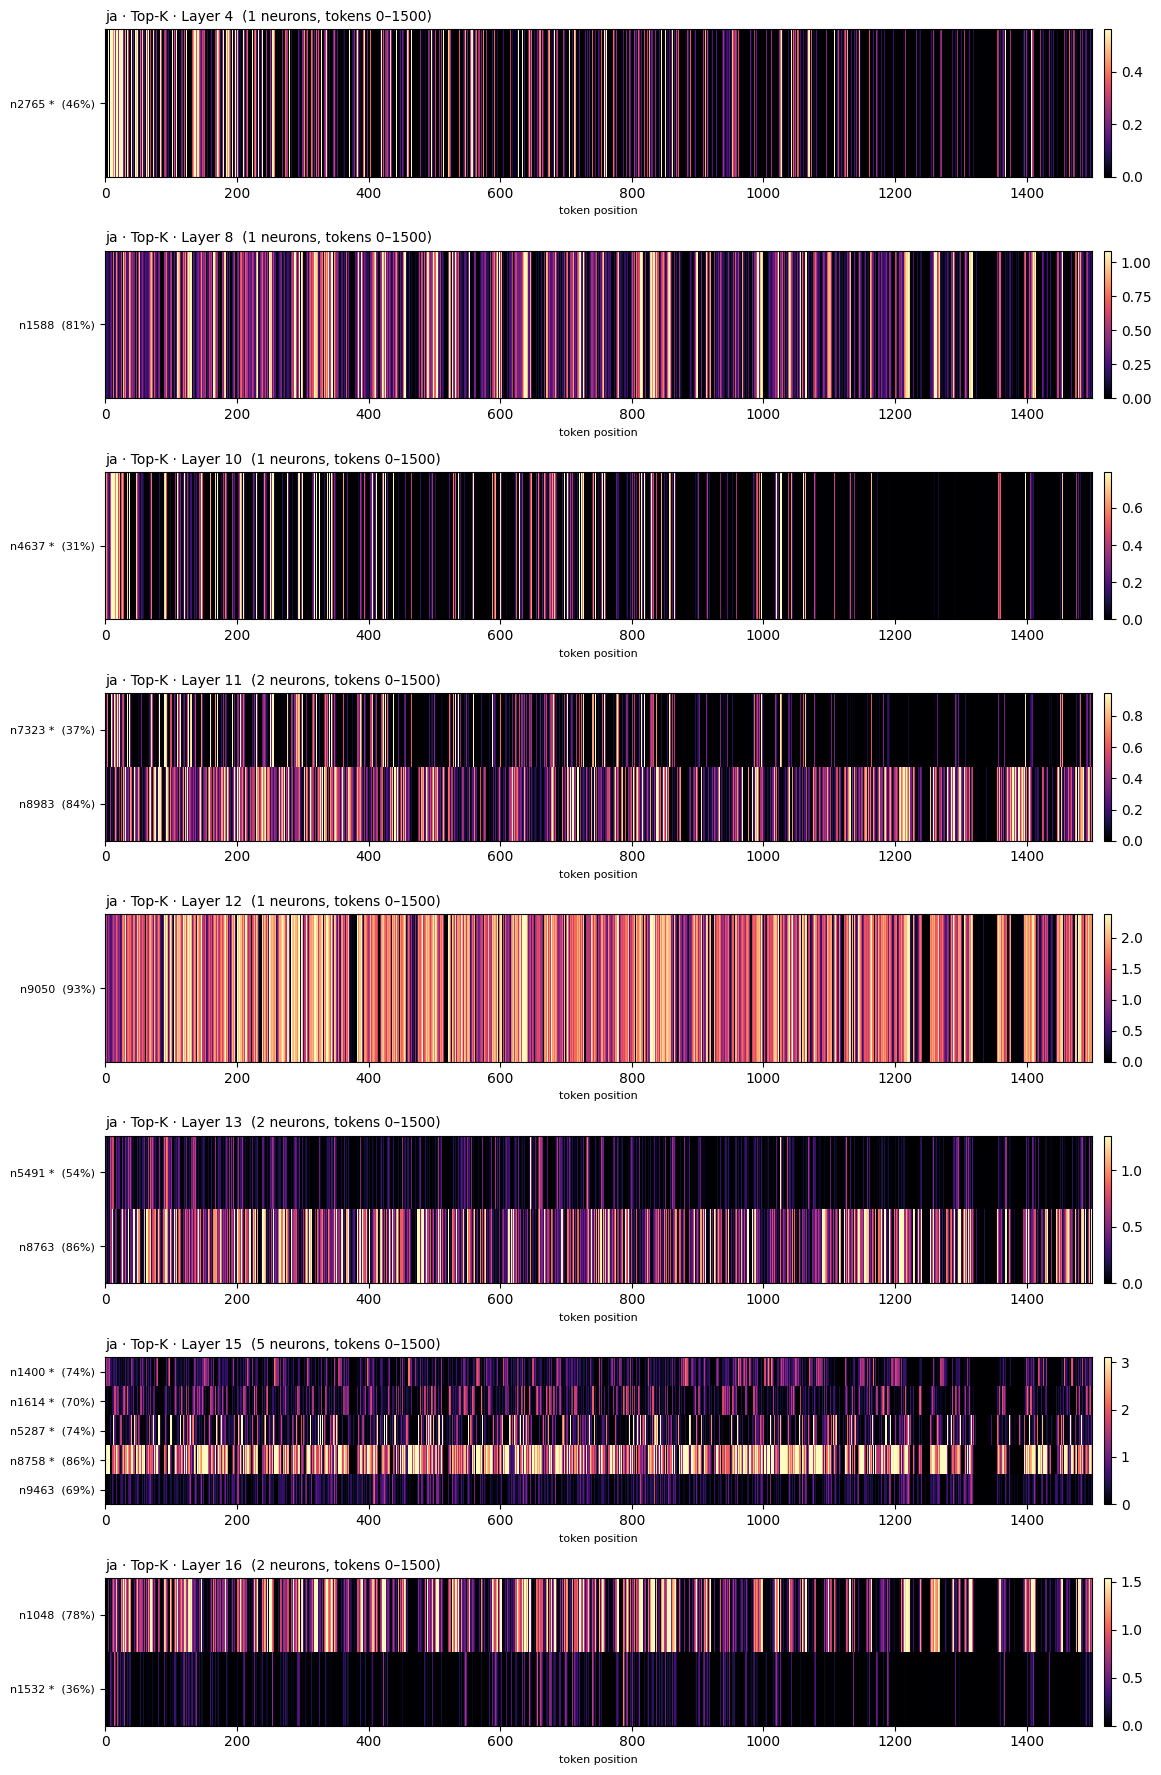

(* = also selected by the other method; parentheses = activation rate)


In [19]:

def show_A(lang, method="Top-K", layers=None, t0=0, t1=2000,
           binarize=False, clip_pct=95, max_layers=8):
    """Plot selected-neuron activations for a language and method."""
    sel = by_layer(sel_topk[lang] if method == "Top-K" else sel_mmr[lang])
    other = set(sel_mmr[lang] if method == "Top-K" else sel_topk[lang])
    if layers is None:
        layers = list(sel.keys())[:max_layers]
    layers = [l for l in layers if l in sel]

    fig, axes = plt.subplots(len(layers), 1,
                             figsize=(13, 0.55 * sum(len(sel[l]) for l in layers) + 1.2 * len(layers)),
                             squeeze=False)
    for ax, l in zip(axes[:, 0], layers):
        js = sorted(sel[l])
        M = load_A(lang, l)[js, t0:t1]
        if binarize:
            img, vmax, cmap = (M > 0).float(), 1, "Greys"
        else:
            img, cmap = M.clamp(min=0), "magma"
            vmax = np.percentile(img.numpy(), clip_pct) or 1
        im = ax.imshow(img, aspect="auto", cmap=cmap, vmin=0, vmax=vmax,
                       interpolation="nearest")
        rates = (M > 0).float().mean(1)
        ax.set_yticks(range(len(js)))
        ax.set_yticklabels([f"n{j}{' *' if (l, j) in other else ''}  ({r:.0%})"
                            for j, r in zip(js, rates)], fontsize=8)
        ax.set_title(f"{lang} · {method} · Layer {l}  ({len(js)} neurons, tokens {t0}–{t1})",
                     fontsize=10, loc="left")
        ax.set_xlabel("token position", fontsize=8)
        plt.colorbar(im, ax=ax, pad=0.01)
    plt.tight_layout(); plt.show()
    print("(* = also selected by the other method; parentheses = activation rate)")


show_A("ja", "Top-K", t0=0, t1=1500)



  [Top-K] n1048–n1532: Jaccard=0.754


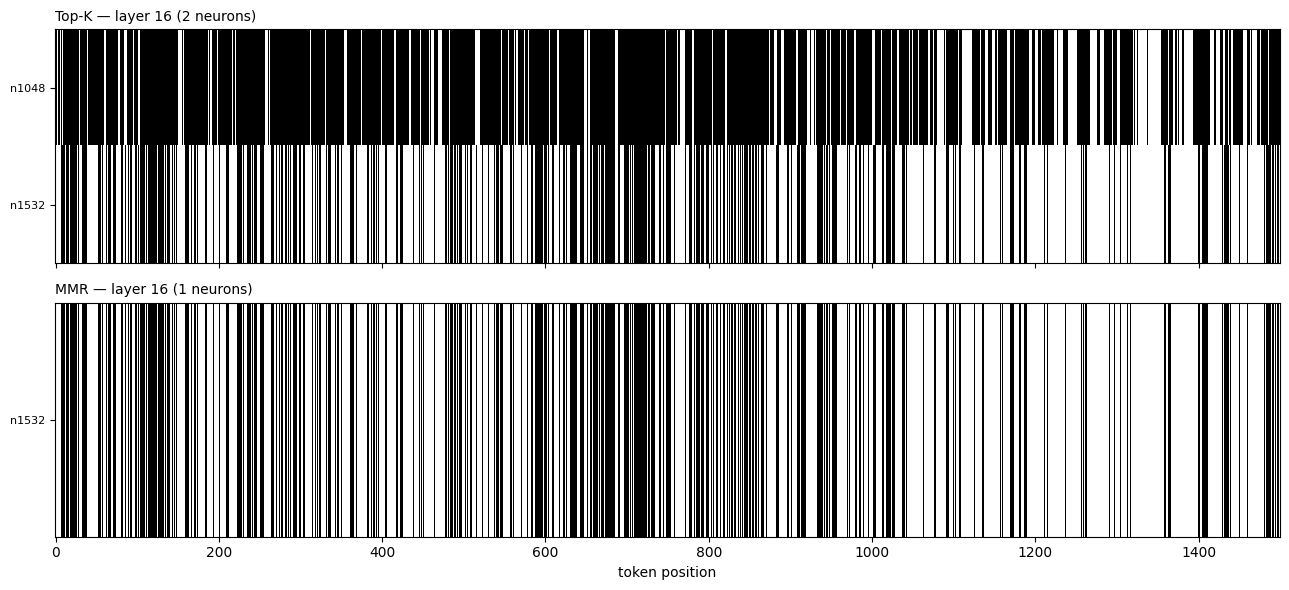

In [20]:

def compare_layer(lang, layer, t0=0, t1=1500, binarize=True):
    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    for ax, (method, sel) in zip(axes, [("Top-K", sel_topk), ("MMR", sel_mmr)]):
        js = sorted(j for l, j in sel[lang] if l == layer)
        if not js:
            ax.set_title(f"{method}: layer {layer} has no selected neurons"); ax.axis("off"); continue
        M = load_A(lang, layer)[js, t0:t1]
        img = (M > 0).float() if binarize else M.clamp(min=0)
        ax.imshow(img, aspect="auto", cmap="Greys" if binarize else "magma",
                  interpolation="nearest")
        ax.set_yticks(range(len(js))); ax.set_yticklabels([f"n{j}" for j in js], fontsize=8)
        ax.set_title(f"{method} — layer {layer} ({len(js)} neurons)", fontsize=10, loc="left")

        B = (load_A(lang, layer)[js] > 0)
        for a in range(len(js)):
            for b in range(a + 1, len(js)):
                inter = (B[a] & B[b]).sum().item(); union = (B[a] | B[b]).sum().item()
                print(f"  [{method}] n{js[a]}–n{js[b]}: Jaccard={inter/max(union,1):.3f}")
    axes[-1].set_xlabel("token position")
    plt.tight_layout(); plt.show()

compare_layer("ja", 16)

## 8. Interpretation

Higher co-membership and fewer distinct features indicate greater structural redundancy. Interpret results within layers and use the same post-activation definition across LAPE, Jaccard, and SNMF. Check robustness over `F ∈ {30, 50, 100}`.


## 9. Paper figure


In [22]:

import math, itertools, torch, numpy as np
from collections import defaultdict
from scipy.stats import mannwhitneyu
import matplotlib.pyplot as plt

LANGS = ["en", "zh", "fr", "es", "vi", "id", "ja"]
DATA_DIR = PACKAGE_ROOT / "work" / "analysis" / "snmf"
ACT_DIR, FAC_DIR = DATA_DIR / "acts", DATA_DIR / "snmf"
MASK_DIR = PACKAGE_ROOT / "artifacts" / "masks"
SNMF_K, SNMF_SPARSITY, T_TOKENS = 50, 0.01, 30000

def normalize_mask(raw):
    out = {}
    for li, lang in enumerate(LANGS):
        pairs = []
        for l, idxs in enumerate(raw[li]):
            idxs = idxs.tolist() if torch.is_tensor(idxs) else list(idxs)
            pairs += [(int(l), int(j)) for j in idxs]
        out[lang] = pairs
    return out

sel_topk = normalize_mask(torch.load(MASK_DIR / "llama2_topk_k30.pth", map_location="cpu"))
sel_mmr  = normalize_mask(torch.load(MASK_DIR / "llama2_mmr_k30_lambda0.6.pth", map_location="cpu"))

_Z = {}
def load_Z(lang, l):
    if (lang, l) not in _Z:
        _Z[(lang, l)] = torch.load(
            f"{FAC_DIR}/snmf_{lang}_l{l}_k{SNMF_K}_p{SNMF_SPARSITY}.pt")["Z"]
    return _Z[(lang, l)]

def feats(lang, l, j):
    return set(torch.nonzero(load_Z(lang, l)[j] != 0).flatten().tolist())


rate = {"Top-K": {}, "MMR": {}}
flags_topk = []
for method, sel_all in [("Top-K", sel_topk), ("MMR", sel_mmr)]:
    for lang in LANGS:
        by_layer = defaultdict(list)
        for (l, j) in sel_all[lang]:
            by_layer[l].append((l, j))
        n_pair = n_share = 0
        for l, ns in by_layer.items():
            for a, b in itertools.combinations(sorted(ns), 2):
                sh = len(feats(lang, *a) & feats(lang, *b)) > 0
                n_pair += 1; n_share += sh
                if method == "Top-K":
                    flags_topk.append((lang, a, b, sh))
        rate[method][lang] = n_share / n_pair if n_pair else float("nan")


def feat_counts(sel_all):
    cnt = defaultdict(int)
    for lang in LANGS:
        for (l, j) in sel_all[lang]:
            fs = feats(lang, l, j)
            if fs:
                f = int(torch.argmax(load_Z(lang, l)[j].abs()))
                cnt[(lang, l, f)] += 1
    return list(cnt.values())
c_tk, c_mm = feat_counts(sel_topk), feat_counts(sel_mmr)


_A = {}
def jaccard(lang, a, b):
    l = a[0]
    if (lang, l) not in _A:
        _A[(lang, l)] = torch.load(f"{ACT_DIR}/acts_{lang}_l{l}.pt") > 0
    A = _A[(lang, l)]
    s1, s2 = A[a[1]], A[b[1]]
    u = (s1 | s2).sum().item()
    return (s1 & s2).sum().item() / u if u else float("nan")

jac_same = [jaccard(lg, a, b) for lg, a, b, sh in flags_topk if sh]
jac_diff = [jaccard(lg, a, b) for lg, a, b, sh in flags_topk if not sh]
u, p = mannwhitneyu(jac_same, jac_diff, alternative="greater")
print(f"rate check: Top-K macro={np.mean(list(rate['Top-K'].values())):.3f}, "
      f"MMR={np.mean(list(rate['MMR'].values())):.3f}")
print(f"Jaccard: same={np.mean(jac_same):.3f} vs diff={np.mean(jac_diff):.3f}, p={p:.3g}")

rate check: Top-K macro=0.658, MMR=0.265
Jaccard: same=0.793 vs diff=0.672, p=1e-17


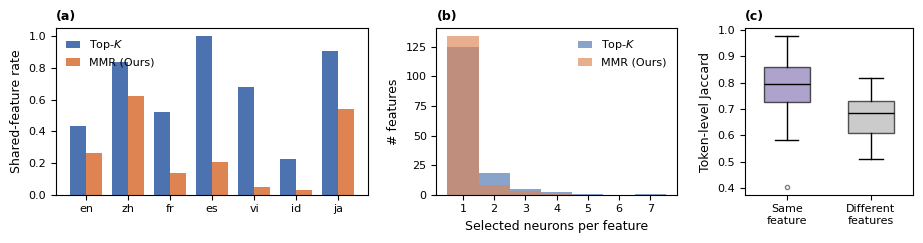

In [24]:

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
C_TK, C_MM = "#4C72B0", "#DD8452"
LBL_TK, LBL_MM = r"Top-$K$", "MMR (Ours)"

fig, axes = plt.subplots(1, 3, figsize=(9.3, 2.5),
                         gridspec_kw={"width_ratios": [1.3, 1.0, 0.7]})


ax = axes[0]
x = np.arange(len(LANGS)); w = 0.38
ax.bar(x - w/2, [rate["Top-K"][l] for l in LANGS], w, label=LBL_TK, color=C_TK)
ax.bar(x + w/2, [rate["MMR"][l]  for l in LANGS], w, label=LBL_MM, color=C_MM)
ax.set_xticks(x, LANGS)
ax.set_ylabel("Shared-feature rate")
ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc="upper left", handlelength=1.3)
ax.set_title("(a)", loc="left", fontweight="bold")


ax = axes[1]
bins = np.arange(0.5, max(c_tk + c_mm) + 1.5)
ax.hist(c_tk, bins=bins, alpha=0.65, color=C_TK, label=LBL_TK)
ax.hist(c_mm, bins=bins, alpha=0.65, color=C_MM, label=LBL_MM)
ax.set_xlabel("Selected neurons per feature")
ax.set_ylabel("# features")
ax.set_xticks(range(1, int(bins[-1]) + 1))
ax.legend(frameon=False, handlelength=1.3)
ax.set_title("(b)", loc="left", fontweight="bold")


ax = axes[2]
bp = ax.boxplot([jac_same, jac_diff], widths=0.55, patch_artist=True,
                medianprops=dict(color="black"),
                flierprops=dict(marker="o", markersize=3, alpha=0.5))
for patch, c in zip(bp["boxes"], ["#8172B3", "#B0B0B0"]):
    patch.set_facecolor(c); patch.set_alpha(0.65)
ax.set_xticks([1, 2], ["Same\nfeature", "Different\nfeatures"])
ax.set_ylabel("Token-level Jaccard")
ax.set_title("(c)", loc="left", fontweight="bold")

fig.tight_layout(w_pad=1.5)
fig.savefig(os.path.join(DATA_DIR, "fig_snmf_redundancy.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(DATA_DIR, "fig_snmf_redundancy.png"), dpi=300, bbox_inches="tight")
plt.show()